In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

CLEANED_PATH = "cleaned_phase1_data.csv"

# خواندن فایل‌ها
udslong = pd.read_csv('alzheimer/udslong_imputed.csv')
mriscan = pd.read_csv('alzheimer/mriscanclean.csv')

# ادغام بر اساس NACCID
combined_df = pd.merge(udslong, mriscan, on='NACCID', how='inner')
print(f"Total merged rows: {len(combined_df)}")


Total merged rows: 1237


In [3]:
# ==========================================================================
# SECTION 1: SETUP, CLEANING & VALIDATION
# ==========================================================================
from pathlib import Path

TABLES = Path("tables")
FIGURES = Path("figures")
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

BRAIN_COLS = [
    "LH_ENTORHINAL_GVOL", "RH_ENTORHINAL_GVOL",
    "LH_PARAHIPPOCAMPAL_GVOL", "RH_PARAHIPPOCAMPAL_GVOL",
    "LH_PRECUNEUS_GVOL", "RH_PRECUNEUS_GVOL",
    "LH_INSULA_GVOL", "RH_INSULA_GVOL",
]
KEY_VARS = (
    ["NACCAGE", "SEX", "EDUC", "INDEPEND", "MOCATOTS", "CDRGLOB", "NACCUDSD",
     "DIABETES", "HYPERTEN", "CBSTROKE"] + BRAIN_COLS
)

if "NACCUDSD" not in combined_df.columns and "NACCUDSD_x" in combined_df.columns:
    combined_df = (combined_df.drop(columns=["NACCUDSD_y"])
                   .rename(columns={"NACCUDSD_x": "NACCUDSD"}))

clean_df = combined_df.copy()
cleaning_log = []

def log_step(variable, rule, n, action, reason):
    cleaning_log.append({"variable": variable, "rule": rule, "n_affected": n,
                         "action": action, "reason": reason})
    print(f"  [{variable}] {rule}: {n} -> {action}")

def set_nan(df, col, mask, rule, reason):
    n = int(mask.sum())
    df.loc[mask, col] = np.nan
    log_step(col, rule, n, "set to NaN", reason)

print("--- 3 & 4. MoCA Score Validation & Cleaning ---")
set_nan(clean_df, "MOCATOTS", clean_df["MOCATOTS"] == 88, "value == 88", "special code")
set_nan(clean_df, "MOCATOTS", clean_df["MOCATOTS"] > 30, "value > 30", "outside valid range")
clean_df["MOCA_ZERO_FLAG"] = clean_df["MOCATOTS"] == 0
log_step("MOCATOTS", "value == 0", int(clean_df["MOCA_ZERO_FLAG"].sum()), "kept + flagged", "extreme value")

valid_moca = clean_df["MOCATOTS"].notna()
clean_df["MOCA_NONINT_FLAG"] = valid_moca & (clean_df["MOCATOTS"] % 1 != 0)
log_step("MOCATOTS", "non-integer value", int(clean_df["MOCA_NONINT_FLAG"].sum()), "kept + flagged", "likely imputed")

SPECIAL_CODES = {"EDUC": [99], "INDEPEND": [9], "HYPERTEN": [9], "DIABETES": [9], "CBSTROKE": [9]}
for col, codes in SPECIAL_CODES.items():
    set_nan(clean_df, col, clean_df[col].isin(codes), f"value in {codes}", "special code")

for col in BRAIN_COLS:
    set_nan(clean_df, col, clean_df[col] <= 0, "volume <= 0", "physically impossible")

def to_binary_history(s, threshold=0.5):
    return (s >= threshold).astype(float).where(s.notna())

BINARY_VARS = {"HYPERTEN": "HYPERTEN_BIN", "DIABETES": "DIABETES_BIN", "CBSTROKE": "STROKE_BIN"}
for col, new_col in BINARY_VARS.items():
    clean_df[new_col] = to_binary_history(clean_df[col])

analysis_vars = [c for c in KEY_VARS if c in clean_df.columns]
summary_df = pd.DataFrame({
    "Valid N": clean_df[analysis_vars].notna().sum(),
    "Missing N": len(clean_df) - clean_df[analysis_vars].notna().sum(),
    "Missing %": (len(clean_df) - clean_df[analysis_vars].notna().sum()) / len(clean_df) * 100,
})
print("\n--- Missingness Summary ---\n", summary_df.round(2))
summary_df.round(2).to_csv(TABLES / "key_variables_missingness.csv")

n_merged = len(clean_df)
analysis_df = clean_df[clean_df["MOCATOTS"].notna()].copy()
print(f"\nFinal analytic sample: {len(analysis_df)} participants")


--- 3 & 4. MoCA Score Validation & Cleaning ---
  [MOCATOTS] value == 88: 4 -> set to NaN
  [MOCATOTS] value > 30: 5 -> set to NaN
  [MOCATOTS] value == 0: 1 -> kept + flagged
  [MOCATOTS] non-integer value: 244 -> kept + flagged
  [EDUC] value in [99]: 2 -> set to NaN
  [INDEPEND] value in [9]: 2 -> set to NaN
  [HYPERTEN] value in [9]: 11 -> set to NaN
  [DIABETES] value in [9]: 8 -> set to NaN
  [CBSTROKE] value in [9]: 3 -> set to NaN
  [LH_ENTORHINAL_GVOL] volume <= 0: 1 -> set to NaN
  [RH_ENTORHINAL_GVOL] volume <= 0: 0 -> set to NaN
  [LH_PARAHIPPOCAMPAL_GVOL] volume <= 0: 0 -> set to NaN
  [RH_PARAHIPPOCAMPAL_GVOL] volume <= 0: 0 -> set to NaN
  [LH_PRECUNEUS_GVOL] volume <= 0: 0 -> set to NaN
  [RH_PRECUNEUS_GVOL] volume <= 0: 0 -> set to NaN
  [LH_INSULA_GVOL] volume <= 0: 0 -> set to NaN
  [RH_INSULA_GVOL] volume <= 0: 0 -> set to NaN

--- Missingness Summary ---
                          Valid N  Missing N  Missing %
NACCAGE                     1237          0       0.00
S

In [4]:
# ==========================================================================
# SECTION 2: VASCULAR HISTORY & OUTLIER REPORTING (NO REMOVAL)
# ==========================================================================
def moca_by_binary(df, col, label_no, label_yes, title, fname):
    d = df[["MOCATOTS", col]].dropna().copy()
    labels = {0.0: label_no, 1.0: label_yes}
    d["group"] = d[col].map(labels)
    g = d.groupby("group")["MOCATOTS"]
    stats = g.agg(n="count", mean="mean", sd="std", median="median",
                  q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75))
    stats["iqr"] = stats["q3"] - stats["q1"]
    stats = stats.reindex([label_no, label_yes])
    print(f"\nMoCA by {title}:\n", stats.round(2))
    stats.round(2).to_csv(TABLES / f"{Path(fname).stem}_stats.csv")

    counts = d["group"].value_counts()
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=d, x="group", y="MOCATOTS", order=[label_no, label_yes], hue="group", palette="Set2", legend=False)
    plt.xticks(range(2), [f"{label_no}\n(n={counts.get(label_no,0)})", f"{label_yes}\n(n={counts.get(label_yes,0)})"])
    plt.title(f"MoCA score by {title}")
    plt.savefig(FIGURES / fname, dpi=300, bbox_inches="tight")
    plt.close()

print("\n--- Vascular history vs MoCA ---")
moca_by_binary(analysis_df, "HYPERTEN_BIN", "No hypertension", "Hypertension history", "hypertension history", "bp_vs_moca_boxplot.png")
moca_by_binary(analysis_df, "DIABETES_BIN", "No diabetes", "Diabetes history", "diabetes history", "diabetes_vs_moca_boxplot.png")
moca_by_binary(analysis_df, "STROKE_BIN", "No stroke", "Stroke history", "stroke history", "stroke_vs_moca_boxplot.png")

print("\n--- MRI Outlier Report (IQR rule, nothing removed) ---")
report_rows, flagged_parts = [], []
for col in BRAIN_COLS:
    s = analysis_df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    low, high = analysis_df[col] < lo, analysis_df[col] > hi
    report_rows.append({"variable": col, "n_valid": len(s), "min": s.min(), "max": s.max(), "Q1": q1, "Q3": q3, "IQR": iqr, "lower": lo, "upper": hi, "n_low": int(low.sum()), "n_high": int(high.sum())})
    analysis_df[f"OUT_{col}"] = low | high
    flagged = analysis_df.loc[low | high, ["NACCID", col]].rename(columns={col: "value"})
    flagged["variable"], flagged["direction"] = col, np.where(flagged["value"] < lo, "low", "high")
    flagged_parts.append(flagged)

outlier_report = pd.DataFrame(report_rows)
outlier_ids = pd.concat(flagged_parts, ignore_index=True)
print(outlier_report.round(1).to_string(index=False))
outlier_report.to_csv(TABLES / "mri_outlier_report.csv", index=False)
outlier_ids.to_csv(TABLES / "mri_outlier_ids.csv", index=False)
analysis_df["MRI_OUTLIER_COUNT"] = analysis_df[[f"OUT_{c}" for c in BRAIN_COLS]].sum(axis=1)



--- Vascular history vs MoCA ---

MoCA by hypertension history:
                         n   mean    sd  median    q1    q3  iqr
group                                                          
No hypertension       738  24.77  4.40    26.0  23.0  27.6  4.6
Hypertension history  479  23.87  4.35    25.0  22.0  27.0  5.0

MoCA by diabetes history:
                      n   mean    sd  median    q1    q3  iqr
group                                                       
No diabetes       1093  24.58  4.37    25.8  23.0  27.0  4.0
Diabetes history   127  23.10  4.62    24.2  21.0  26.0  5.0

MoCA by stroke history:
                    n   mean    sd  median    q1    q3  iqr
group                                                     
No stroke       1208  24.41  4.42    25.4  23.0  27.0  4.0
Stroke history    17  24.36  4.41    25.0  22.0  28.0  6.0

--- MRI Outlier Report (IQR rule, nothing removed) ---
               variable  n_valid   min     max     Q1      Q3    IQR  lower   upper  n_l

In [5]:
# ==========================================================================
# SECTION 3: CORRELATION & FINAL EXPORT
# ==========================================================================
print("\n" + "=" * 50 + "\n--- BRAIN CORRELATIONS ---\n" + "=" * 50)
regions_to_analyze = {
    "ENTORHINAL": ['LH_ENTORHINAL_GVOL', 'RH_ENTORHINAL_GVOL'],
    "PARAHIPPOCAMPAL": ['LH_PARAHIPPOCAMPAL_GVOL', 'RH_PARAHIPPOCAMPAL_GVOL'],
    "PRECUNEUS": ['LH_PRECUNEUS_GVOL', 'RH_PRECUNEUS_GVOL'],
    "INSULA": ['LH_INSULA_GVOL', 'RH_INSULA_GVOL']
}

for group_name, columns in regions_to_analyze.items():
    for col in columns:
        valid_data = analysis_df[['MOCATOTS', col]].dropna()
        if not valid_data.empty:
            r_val = valid_data[col].corr(valid_data['MOCATOTS'])
            print(f"{col:<25} | Pearson R: {r_val:.4f}")
            plt.figure(figsize=(7, 5))
            sns.regplot(x=col, y='MOCATOTS', data=valid_data, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
            plt.title(f'{col} vs MoCA Score')
            plt.savefig(FIGURES / f"{col.lower()}_vs_moca_scatter.png", dpi=300)
            plt.close()

# Final Clean Save
pd.DataFrame(cleaning_log).to_csv(TABLES / "cleaning_log.csv", index=False)
analysis_df.to_csv("cleaned_phase1_data.csv", index=False)
print(f"\n[DONE] All files saved in 'tables/' and 'figures/'.")
print(f"[DONE] Final dataset saved as 'cleaned_phase1_data.csv'")



--- BRAIN CORRELATIONS ---
LH_ENTORHINAL_GVOL        | Pearson R: 0.2119
RH_ENTORHINAL_GVOL        | Pearson R: 0.2070
LH_PARAHIPPOCAMPAL_GVOL   | Pearson R: 0.2152
RH_PARAHIPPOCAMPAL_GVOL   | Pearson R: 0.2396
LH_PRECUNEUS_GVOL         | Pearson R: 0.2564
RH_PRECUNEUS_GVOL         | Pearson R: 0.2292
LH_INSULA_GVOL            | Pearson R: 0.1303
RH_INSULA_GVOL            | Pearson R: 0.1371

[DONE] All files saved in 'tables/' and 'figures/'.
[DONE] Final dataset saved as 'cleaned_phase1_data.csv'


In [ ]:
import os
import pandas as pd

if "combined_df" not in globals():
    if os.path.exists("cleaned_phase1_data.csv"):
        combined_df = pd.read_csv("cleaned_phase1_data.csv")
    elif os.path.exists("tables/cleaned_phase1_data.csv"):
        combined_df = pd.read_csv("tables/cleaned_phase1_data.csv")
    else:
        # اگر فایل نبود، از مسیر اصلی می‌خوانیم
        combined_df = pd.read_csv("alz/alzheimer/udslong_imputed.csv")
    print(f"[OK] Data loaded. Shape: {combined_df.shape}")
else:
    print(f"[OK] combined_df is already in memory. Shape: {combined_df.shape}")


[OK] combined_df is already in memory. Shape: (1228, 318)


In [7]:
# Block 0.5: Verify which file is loaded
import os
print("Loaded file:", getattr(combined_df, "attrs", {}).get("source", "unknown"))
print("Shape:", combined_df.shape)
print("MoCA zeros:", (combined_df["MOCATOTS"] == 0).sum())
print("MoCA < 10:", (combined_df["MOCATOTS"] < 10).sum())
print("MoCA describe:\n", combined_df["MOCATOTS"].describe())


Loaded file: unknown
Shape: (1228, 318)
MoCA zeros: 1
MoCA < 10: 20
MoCA describe:
 count    1228.000000
mean       24.392997
std         4.424823
min         0.000000
25%        23.000000
50%        25.400000
75%        27.000000
max        30.000000
Name: MOCATOTS, dtype: float64


In [ ]:
# Frequency and Percentage for Categorical Variables
cat_vars = ["SEX", "INDEPEND", "HYPERTEN", "DIABETES", "CBSTROKE"]

for var in cat_vars:
    if var in combined_df.columns:
        freq = combined_df[var].value_counts(dropna=False).sort_index()
        pct = (freq / len(combined_df) * 100).round(1)
        
        df_cat = freq.to_frame("Frequency (N)").assign(Percent=pct)
        print(f"\n--- Frequency Table for: {var} ---")
        print(df_cat)
    else:
        print(f"[Warning] Variable '{var}' not found in DataFrame.")



--- Frequency Table for: SEX ---
     Frequency (N)  Percent
SEX                        
1.0            496     40.4
2.0            732     59.6

--- Frequency Table for: INDEPEND ---
          Frequency (N)  Percent
INDEPEND                        
1.0                1116     90.9
2.0                  83      6.8
3.0                  26      2.1
4.0                   1      0.1
NaN                   2      0.2

--- Frequency Table for: HYPERTEN ---
          Frequency (N)  Percent
HYPERTEN                        
0.0                 726     59.1
0.2                   7      0.6
0.4                   5      0.4
0.6                   7      0.6
1.0                 442     36.0
1.8                   1      0.1
2.0                  28      2.3
2.4                   1      0.1
NaN                  11      0.9

--- Frequency Table for: DIABETES ---
          Frequency (N)  Percent
DIABETES                        
0.0                1084     88.3
0.2                   7      0.6
0.4        

In [6]:
import numpy as np

# Block 2: Summary Statistics for Numerical Variables
num_vars = ["NACCAGE", "MOCATOTS", "LH_ENTORHINAL_GVOL", "RH_ENTORHINAL_GVOL", 
            "LH_PRECUNEUS_GVOL", "RH_PRECUNEUS_GVOL"]

summary_list = []

for var in num_vars:
    if var in combined_df.columns:
        s = combined_df[var].dropna()
        summary_list.append({
            "Variable": var,
            "Mean": round(s.mean(), 2),
            "Std": round(s.std(), 2),
            "Median": round(s.median(), 2),
            "IQR": round(s.quantile(0.75) - s.quantile(0.25), 2),
            "Min": round(s.min(), 2),
            "Max": round(s.max(), 2),
            "Missing N": combined_df[var].isna().sum()
        })

df_summary = pd.DataFrame(summary_list).set_index("Variable")
print("\n--- Summary Statistics for Numerical Variables ---")
print(df_summary)



--- Summary Statistics for Numerical Variables ---
                       Mean      Std  Median      IQR    Min      Max  \
Variable                                                                
NACCAGE               68.18     8.06    68.0    11.00   41.0     91.0   
MOCATOTS              24.39     4.42    25.4     4.00    0.0     30.0   
LH_ENTORHINAL_GVOL  1556.67   411.74  1545.0   493.00  211.0   4265.0   
RH_ENTORHINAL_GVOL  1526.25   405.23  1513.5   456.50    6.0   5334.0   
LH_PRECUNEUS_GVOL   8494.67  1416.94  8529.0  1639.75  124.0  12914.0   
RH_PRECUNEUS_GVOL   9266.54  1541.99  9228.0  1815.75  716.0  14351.0   

                    Missing N  
Variable                       
NACCAGE                     0  
MOCATOTS                    0  
LH_ENTORHINAL_GVOL          1  
RH_ENTORHINAL_GVOL          0  
LH_PRECUNEUS_GVOL           0  
RH_PRECUNEUS_GVOL           0  


In [8]:
# Block 5.1: Fix HYPERTEN -> HYPERTEN_BIN
import numpy as np
import pandas as pd

# show raw values first
print("Raw value counts:")
print(combined_df["HYPERTEN"].value_counts(dropna=False).sort_index())

# 9 = missing code in NACC; everything else > 0 means "history of hypertension"
raw = combined_df["HYPERTEN"].replace(9, np.nan)

combined_df["HYPERTEN_BIN"] = np.where(raw.isna(), np.nan,
                                np.where(raw > 0, 1.0, 0.0))

print("\nAfter cleaning:")
print(combined_df["HYPERTEN_BIN"].value_counts(dropna=False).sort_index())
print("Missing:", combined_df["HYPERTEN_BIN"].isna().sum())


Raw value counts:
HYPERTEN
0.0    726
0.2      7
0.4      5
0.6      7
1.0    442
1.8      1
2.0     28
2.4      1
NaN     11
Name: count, dtype: int64

After cleaning:
HYPERTEN_BIN
0.0    726
1.0    491
NaN     11
Name: count, dtype: int64
Missing: 11


In [9]:
# Block 5.2: MoCA by corrected hypertension groups
g = combined_df.groupby("HYPERTEN_BIN")["MOCATOTS"]

summary = pd.DataFrame({
    "n":      g.count(),
    "mean":   g.mean().round(2),
    "sd":     g.std().round(2),
    "median": g.median().round(1),
    "q1":     g.quantile(0.25).round(1),
    "q3":     g.quantile(0.75).round(1),
})
summary["iqr"] = (summary["q3"] - summary["q1"]).round(1)

summary.index = summary.index.map({0.0: "No hypertension", 1.0: "Hypertension history"})
print(summary)


                        n   mean    sd  median    q1    q3  iqr
HYPERTEN_BIN                                                   
No hypertension       726  24.76  4.42    26.0  23.0  27.6  4.6
Hypertension history  491  23.91  4.33    25.0  22.0  27.0  5.0


In [10]:
# Verify participant structure and merge integrity (task J2 & J3)
import pandas as pd

uds = pd.read_csv("alzheimer/udslong_imputed.csv")
mri = pd.read_csv("alzheimer/mriscanclean.csv")

print("UDS rows:", len(uds), "| unique NACCID:", uds["NACCID"].nunique())
print("MRI rows:", len(mri), "| unique NACCID:", mri["NACCID"].nunique())

# J2: check for repeated participants
print("Duplicated NACCID in UDS:", uds["NACCID"].duplicated().sum())
print("Duplicated NACCID in MRI:", mri["NACCID"].duplicated().sum())

# J3: data flow of the merge
merged = uds.merge(mri, on="NACCID", how="inner")
print("Inner merge result:", merged.shape)
print("UDS without MRI match:", len(set(uds["NACCID"]) - set(mri["NACCID"])))
print("MRI without UDS match:", len(set(mri["NACCID"]) - set(uds["NACCID"])))


UDS rows: 1237 | unique NACCID: 1237
MRI rows: 1237 | unique NACCID: 1237
Duplicated NACCID in UDS: 0
Duplicated NACCID in MRI: 0
Inner merge result: (1237, 305)
UDS without MRI match: 0
MRI without UDS match: 0


In [ ]:
import pandas as pd, numpy as np
uds = pd.read_csv('alzheimer/udslong_imputed.csv')
mri = pd.read_csv('alzheimer/mriscanclean.csv')
d = uds.merge(mri, on='NACCID', how='inner')
d = d[d['MOCATOTS'] <= 30].copy()        

CUTOFF = 26                               

def binary_history(s):                    
    s = s.replace(9, np.nan)
    return (s.round() > 0).where(s.notna()).astype(float)

d['A'] = binary_history(d['HYPERTEN'])
d['D'] = binary_history(d['DIABETES'])
d['B'] = (d['MOCATOTS'] < CUTOFF).astype(float)

for c in ['LH_ENTORHINAL_GVOL', 'RH_ENTORHINAL_GVOL']:
    d.loc[d[c] <= 0, c] = np.nan          
d['BILAT_ENTORHINAL'] = d['LH_ENTORHINAL_GVOL'] + d['RH_ENTORHINAL_GVOL']

q1 = d.groupby('SEX')['BILAT_ENTORHINAL'].transform(lambda x: x.quantile(0.25))
d['C'] = (d['BILAT_ENTORHINAL'] < q1).where(d['BILAT_ENTORHINAL'].notna()).astype(float)

print(d[['A','D','B','C']].apply(lambda s: s.value_counts(dropna=False)))

       A     D      B    C
0.0  738  1093  574.0  920
1.0  479   127  654.0  307
NaN   11     8    NaN    1


In [8]:
def add_margins(t):
    """Append a 'Total' row and column to a 2x2 table."""
    t = t.copy()
    t['Total'] = t.sum(axis=1)
    t.loc['Total'] = t.sum(axis=0)
    return t


def joint_table(d, x, y):
    """Counts and joint probabilities for two binary events (0/1); uses only rows valid in both columns."""
    s = d[[x, y]].dropna().astype(float)
    n = len(s)
    counts = (pd.crosstab(s[x], s[y])
                .reindex(index=[0.0, 1.0], columns=[0.0, 1.0], fill_value=0))
    joint = counts / n
    return n, counts, joint

In [9]:
n, counts, joint = joint_table(d, 'A', 'B')
print("valid n =", n)

display(add_margins(counts))           # frequencies with totals
display(add_margins(joint).round(4))   # joint and marginal probabilities

p_A  = joint.loc[1.0].sum()    # P(A)        = sum of row A=1
p_B  = joint[1.0].sum()        # P(B)        = sum of column B=1
p_AB = joint.loc[1.0, 1.0]     # P(A and B)
print(f"P(A)={p_A:.4f}  P(B)={p_B:.4f}  P(A and B)={p_AB:.4f}")

valid n = 1217


B,0.0,1.0,Total
A,,,
0.0,384,354,738
1.0,187,292,479
Total,571,646,1217


B,0.0,1.0,Total
A,,,
0.0,0.3155,0.2909,0.6064
1.0,0.1537,0.2399,0.3936
Total,0.4692,0.5308,1.0000


P(A)=0.3936  P(B)=0.5308  P(A and B)=0.2399


In [10]:
pairs = [('A', 'B'), ('D', 'B'), ('C', 'B'), ('A', 'C')]
rows = []
for x, y in pairs:
    n, counts, joint = joint_table(d, x, y)
    rows.append({
        'pair': f'{x} & {y}',
        'valid_n': n,
        'P_first': joint.loc[1.0].sum(),
        'P_second': joint[1.0].sum(),
        'P_joint': joint.loc[1.0, 1.0],
        'joint_count': int(counts.loc[1.0, 1.0]),
    })
summary = pd.DataFrame(rows).round(4)
summary

,pair,valid_n,P_first,P_second,P_joint,joint_count
0,A & B,1217,0.3936,0.5308,0.2399,292
1,D & B,1220,0.1041,0.5295,0.0705,86
2,C & B,1227,0.2502,0.5330,0.1793,220
3,A & C,1216,0.3939,0.2484,0.1118,136


In [11]:
import os
os.makedirs('reports/phase2', exist_ok=True)
summary.to_csv('reports/phase2/table_marginal_joint.csv', index=False)

In [3]:
import os
import numpy as np
import pandas as pd

uds = pd.read_csv('alzheimer/udslong_imputed.csv')
mri = pd.read_csv('alzheimer/mriscanclean.csv')
d = uds.merge(mri, on='NACCID', how='inner')
d = d[d['MOCATOTS'] <= 30].copy()          # Phase 1 rule: 9 invalid MoCA rows dropped (n=1228)

def binary_history(s):
    s = s.replace(9, np.nan)               # code 9 = unknown
    return (s.round() > 0).where(s.notna()).astype(float)

d['A'] = binary_history(d['HYPERTEN'])
d['D'] = binary_history(d['DIABETES'])
d['B'] = (d['MOCATOTS'] < 26).astype(float)

for c in ['LH_ENTORHINAL_GVOL', 'RH_ENTORHINAL_GVOL']:
    d.loc[d[c] <= 0, c] = np.nan
d['BILAT_ENTORHINAL'] = d['LH_ENTORHINAL_GVOL'] + d['RH_ENTORHINAL_GVOL']

q1 = d.groupby('SEX')['BILAT_ENTORHINAL'].transform(lambda x: x.quantile(0.25))
d['C'] = (d['BILAT_ENTORHINAL'] < q1).where(d['BILAT_ENTORHINAL'].notna()).astype(float)

print(d[['A', 'D', 'B', 'C']].apply(lambda s: s.value_counts(dropna=False)))

       A     D      B    C
0.0  738  1093  574.0  920
1.0  479   127  654.0  307
NaN   11     8    NaN    1


In [4]:
def conditional(d, event, given):
    """P(event | given) and P(event | not given), using rows valid in both columns."""
    s = d[[event, given]].dropna().astype(float)
    res = {}
    for g in [1.0, 0.0]:
        sub = s[s[given] == g]
        res[g] = (int(sub[event].sum()), len(sub))
    k1, n1 = res[1.0]
    k0, n0 = res[0.0]
    p1, p0 = k1 / n1, k0 / n0
    return {
        'conditional': f'P({event}|{given})',
        'k_given': k1, 'n_given': n1, 'p_given': p1,
        'comparison': f'P({event}|not {given})',
        'k_not': k0, 'n_not': n0, 'p_not': p0,
        'diff': p1 - p0,          # difference in probabilities (descriptive)
        'ratio': p1 / p0,         # ratio of probabilities (descriptive)
    }

In [5]:
specs = [('B', 'A'), ('B', 'C'), ('B', 'D'), ('C', 'A'), ('A', 'B')]
cond = pd.DataFrame([conditional(d, e, g) for e, g in specs]).round(4)
cond

,conditional,k_given,n_given,p_given,comparison,k_not,n_not,p_not,diff,ratio
0,P(B|A),292,479,0.6096,P(B|not A),354,738,0.4797,0.1299,1.2709
1,P(B|C),220,307,0.7166,P(B|not C),434,920,0.4717,0.2449,1.5191
2,P(B|D),86,127,0.6772,P(B|not D),560,1093,0.5124,0.1648,1.3217
3,P(C|A),136,479,0.2839,P(C|not A),166,737,0.2252,0.0587,1.2606
4,P(A|B),292,646,0.4520,P(A|not B),187,571,0.3275,0.1245,1.3802


In [6]:
s = d[['A', 'C', 'B']].dropna()
comb = (s.groupby(['A', 'C'])['B']
          .agg(k='sum', n='size', p='mean')
          .round(4)
          .reset_index())
comb

,A,C,k,n,p
0,0.0,0.0,238.0,571,0.4168
1,0.0,1.0,116.0,166,0.6988
2,1.0,0.0,193.0,343,0.5627
3,1.0,1.0,99.0,136,0.7279


In [7]:
s2 = d[['A', 'B']].dropna()
pA = s2['A'].mean()
total = (s2.loc[s2.A == 1, 'B'].mean() * pA
         + s2.loc[s2.A == 0, 'B'].mean() * (1 - pA))
print(round(total, 4), round(s2['B'].mean(), 4))   # should be equal

import os
os.makedirs('reports/phase2', exist_ok=True)
cond.to_csv('reports/phase2/table_conditional.csv', index=False)
comb.to_csv('reports/phase2/table_conditional_AC.csv', index=False)

0.5308 0.5308


In [11]:
def independence_check(d, x, y):
    """Compare observed P(x and y) with P(x)*P(y) and P(y|x) with P(y)."""
    s = d[[x, y]].dropna().astype(float)
    n = len(s)
    p_x = s[x].mean()
    p_y = s[y].mean()
    p_xy = ((s[x] == 1) & (s[y] == 1)).mean()
    p_y_given_x = s.loc[s[x] == 1, y].mean()
    p_y_given_notx = s.loc[s[x] == 0, y].mean()
    return {
        'pair': f'{x} & {y}',
        'n': n,
        'P_x': p_x,
        'P_y': p_y,
        'P_joint_obs': p_xy,
        'P_joint_if_indep': p_x * p_y,
        'count_obs': int(round(p_xy * n)),
        'count_if_indep': p_x * p_y * n,
        'ratio_joint': p_xy / (p_x * p_y),
        'P_y_given_x': p_y_given_x,
        'P_y_given_notx': p_y_given_notx,
        'diff_cond_vs_marg': p_y_given_x - p_y,
    }

In [9]:
pairs = [('A', 'B'), ('C', 'B'), ('D', 'B'), ('A', 'C')]
indep = pd.DataFrame([independence_check(d, x, y) for x, y in pairs]).round(4)
indep

,pair,n,P_x,P_y,P_joint_obs,P_joint_if_indep,count_obs,count_if_indep,ratio_joint,P_y_given_x,P_y_given_notx,diff_cond_vs_marg
0,A & B,1217,0.3936,0.5308,0.2399,0.2089,292,254.2597,1.1484,0.6096,0.4797,0.0788
1,C & B,1227,0.2502,0.5330,0.1793,0.1334,220,163.6333,1.3445,0.7166,0.4717,0.1836
2,D & B,1220,0.1041,0.5295,0.0705,0.0551,86,67.2475,1.2789,0.6772,0.5124,0.1477
3,A & C,1216,0.3939,0.2484,0.1118,0.0978,136,118.9622,1.1432,0.2839,0.2252,0.0356


In [10]:
def conditional_diff_scale(d, x, y):
    """Rough standard error of P(y|x) - P(y|not x). A scale for sampling noise, NOT a formal test."""
    s = d[[x, y]].dropna().astype(float)
    a = s.loc[s[x] == 1, y]
    b = s.loc[s[x] == 0, y]
    diff = a.mean() - b.mean()
    se = np.sqrt(a.mean() * (1 - a.mean()) / len(a) + b.mean() * (1 - b.mean()) / len(b))
    return {'pair': f'{x} & {y}', 'diff': diff, 'approx_se': se, 'diff_over_se': diff / se}

scale = pd.DataFrame([conditional_diff_scale(d, x, y) for x, y in pairs]).round(4)
scale

,pair,diff,approx_se,diff_over_se
0,A & B,0.1299,0.0289,4.4963
1,C & B,0.2449,0.0305,8.0195
2,D & B,0.1648,0.0442,3.7324
3,A & C,0.0587,0.0257,2.2823


In [12]:
s = d[['A', 'B']].dropna().astype(float)
observed = pd.crosstab(s['A'], s['B'])
expected = pd.DataFrame(
    np.outer(observed.sum(axis=1), observed.sum(axis=0)) / len(s),
    index=observed.index, columns=observed.columns
).round(1)
display(observed)   # observed counts
display(expected)   # counts expected under independence

B,0.0,1.0
A,,
0.0,384,354
1.0,187,292


B,0.0,1.0
A,,
0.0,346.3,391.7
1.0,224.7,254.3


In [13]:
os.makedirs('reports/phase2', exist_ok=True)
indep.to_csv('reports/phase2/table_independence.csv', index=False)
scale.to_csv('reports/phase2/table_independence_scale.csv', index=False)

In [14]:
from math import comb

N = len(d)
m = 30
b = d['B'].astype(int).values          # 1 = MoCA < 26, no missing
p_hat = b.mean()

print(f"N={N}, events={b.sum()}, p_hat={p_hat:.4f}")
print(f"E(K)={m*p_hat:.2f}  Var(K)={m*p_hat*(1-p_hat):.2f}  SD={(m*p_hat*(1-p_hat))**0.5:.2f}")
print(f"m*p={m*p_hat:.2f}  m*(1-p)={m*(1-p_hat):.2f}  m/N={m/N:.4f}  FPC={(N-m)/(N-1):.4f}")

def binom_pmf(k, m, p):
    return comb(m, k) * p**k * (1 - p)**(m - k)

N=1228, events=654, p_hat=0.5326
E(K)=15.98  Var(K)=7.47  SD=2.73
m*p=15.98  m*(1-p)=14.02  m/N=0.0244  FPC=0.9764


In [15]:
rng = np.random.default_rng(2026)      # fixed seed for reproducibility
R = 20000
K = np.array([rng.choice(b, m, replace=False).sum() for _ in range(R)])

print("simulated mean/var:", K.mean().round(2), K.var(ddof=1).round(2))

ks = np.arange(8, 25)
cmp = pd.DataFrame({
    'k': ks,
    'binomial': [binom_pmf(k, m, p_hat) for k in ks],
    'simulated': [(K == k).mean() for k in ks],
}).round(4)
display(cmp)

tvd = 0.5 * sum(abs(binom_pmf(k, m, p_hat) - (K == k).mean()) for k in range(m + 1))
print("total variation distance:", round(tvd, 4))

simulated mean/var: 16.0 7.26


,k,binomial,simulated
0,8,0.0021,0.0018
1,9,0.0057,0.0050
2,10,0.0137,0.0130
3,11,0.0283,0.0278
4,12,0.0511,0.0490
5,13,0.0806,0.0792
6,14,0.1115,0.1114
7,15,0.1355,0.1368
8,16,0.1448,0.1459
9,17,0.1358,0.1369


total variation distance: 0.011


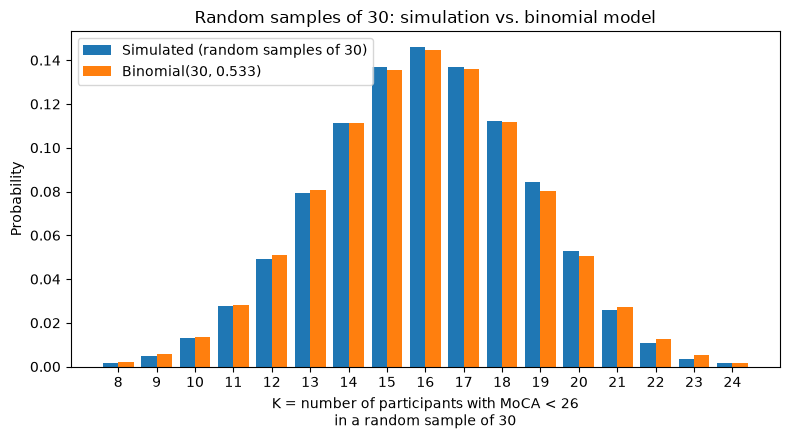

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(cmp['k'] - 0.2, cmp['simulated'], width=0.4, label='Simulated (random samples of 30)')
ax.bar(cmp['k'] + 0.2, cmp['binomial'],  width=0.4, label=f'Binomial(30, {p_hat:.3f})')
ax.set_xticks(cmp['k'])                                  # integer ticks only
ax.set_xlabel('K = number of participants with MoCA < 26\nin a random sample of 30')
ax.set_ylabel('Probability')
ax.set_title('Random samples of 30: simulation vs. binomial model')
ax.legend(loc='upper left')                              # keeps legend off the bars
plt.tight_layout()
plt.savefig('figures/phase2_binomial_vs_simulation.png', dpi=200)
plt.show()

In [17]:
d['age_group'] = pd.cut(d['NACCAGE'], [0, 60, 70, 80, 100],
                        labels=['<=60', '61-70', '71-80', '>80'])
strata = (d.groupby('age_group', observed=True)['B']
            .agg(n='size', k='sum', p='mean'))
strata['E_K_m30'] = strata['p'] * m
strata['SD_K_m30'] = np.sqrt(m * strata['p'] * (1 - strata['p']))
display(strata.round(3))

# Tail probabilities: pooled p vs the stratum's own p
def tail_ge(k0, m, p):  return sum(binom_pmf(k, m, p) for k in range(k0, m + 1))
def tail_le(k0, m, p):  return sum(binom_pmf(k, m, p) for k in range(0, k0 + 1))

p_71_80 = strata.loc['71-80', 'p']
p_le_60 = strata.loc['<=60', 'p']
print("P(K>=22): pooled p =", round(tail_ge(22, m, p_hat), 3), "| age 71-80 p =", round(tail_ge(22, m, p_71_80), 3))
print("P(K<=10): pooled p =", round(tail_le(10, m, p_hat), 3), "| age <=60 p =", round(tail_le(10, m, p_le_60), 3))

,n,k,p,E_K_m30,SD_K_m30
age_group,,,,,
<=60,198,68.0,0.343,10.303,2.601
61-70,552,272.0,0.493,14.783,2.738
71-80,409,266.0,0.650,19.511,2.612
>80,69,48.0,0.696,20.870,2.520


P(K>=22): pooled p = 0.02 | age 71-80 p = 0.226
P(K<=10): pooled p = 0.022 | age <=60 p = 0.538


In [18]:
blocks = np.array([b[i:i + m].sum() for i in range(0, N - m + 1, m)])
print("blocks:", len(blocks), "mean:", blocks.mean().round(2),
      "var:", blocks.var(ddof=1).round(2), "min/max:", blocks.min(), blocks.max())
print("binomial variance:", round(m * p_hat * (1 - p_hat), 2))

perm_vars = []
for _ in range(5000):
    sh = rng.permutation(b)
    perm_vars.append(np.var([sh[i:i + m].sum() for i in range(0, N - m + 1, m)], ddof=1))
perm_vars = np.array(perm_vars)
print("permutation 2.5/50/97.5%:", np.percentile(perm_vars, [2.5, 50, 97.5]).round(2))
print("share of permutations with var >= observed:", (perm_vars >= blocks.var(ddof=1)).mean())

blocks: 40 mean: 16.12 var: 23.45 min/max: 6 27
binomial variance: 7.47
permutation 2.5/50/97.5%: [ 4.59  7.38 11.2 ]
share of permutations with var >= observed: 0.0


In [20]:
os.makedirs('reports/phase2', exist_ok=True)
cmp.to_csv('reports/phase2/table_binomial_vs_simulation.csv', index=False)
strata.round(4).to_csv('reports/phase2/table_binomial_age_strata.csv')

In [23]:
from scipy import stats
import matplotlib.pyplot as plt

def distribution_summary(x):
    x = x.dropna()
    n = len(x); mu = x.mean(); sd = x.std(ddof=1)
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (x - mu) / sd
    return {
        'n': n, 'mean': mu, 'sd': sd, 'variance': sd**2,
        'median': med, 'q1': q1, 'q3': q3, 'iqr': iqr,
        'min': x.min(), 'max': x.max(),
        'skewness': stats.skew(x, bias=False),
        'excess_kurtosis': stats.kurtosis(x, bias=False),
        'outliers_low': int((x < low_fence).sum()),
        'outliers_high': int((x > high_fence).sum()),
        'within_1sd': (z.abs() <= 1).mean(),
        'within_2sd': (z.abs() <= 2).mean(),
        'within_3sd': (z.abs() <= 3).mean(),
        'shapiro_W': stats.shapiro(x).statistic,
    }

summary6 = pd.DataFrame({
    'MoCA': distribution_summary(d['MOCATOTS']),
    'BILAT_ENTORHINAL': distribution_summary(d['BILAT_ENTORHINAL']),
}).round(4)
summary6

,MoCA,BILAT_ENTORHINAL
n,1228.0000,1227.0000
mean,24.3930,3083.8818
sd,4.4248,723.9648
variance,19.5791,524125.0717
median,25.4000,3075.0000
q1,23.0000,2630.0000
q3,27.0000,3492.0000
iqr,4.0000,862.0000
min,0.0000,366.0000
max,30.0000,8036.0000


In [30]:
def quantile_check(x, probs=(0.025, 0.25, 0.5, 0.75, 0.975)):
    """Observed quantiles vs. quantiles of a normal model fitted with the same mean and SD."""
    x = x.dropna()
    mu, sd = x.mean(), x.std(ddof=1)
    out = pd.DataFrame({
        'prob': probs,
        'observed': [x.quantile(p) for p in probs],
        'normal_model': [stats.norm.ppf(p, mu, sd) for p in probs],
    })
    out[['observed', 'normal_model']] = out[['observed', 'normal_model']].round(2)
    return out

print("MoCA")
display(quantile_check(d['MOCATOTS']))

print("Bilateral entorhinal volume")
display(quantile_check(d['BILAT_ENTORHINAL']))

# Ceiling effect for MoCA
x = d['MOCATOTS']
print("score == 30:", (x == 30).sum(), f"({(x == 30).mean():.3f})")
print("score >= 29:", (x >= 29).sum(), "| score >= 28:", (x >= 28).sum())
print("P(X > 30) under fitted normal:",
      round(1 - stats.norm.cdf(30, x.mean(), x.std(ddof=1)), 4))

# Extreme entorhinal values in SD units
e = d['BILAT_ENTORHINAL'].dropna()
print("z of max / min:",
      round((e.max() - e.mean()) / e.std(ddof=1), 2),
      round((e.min() - e.mean()) / e.std(ddof=1), 2))

MoCA


,prob,observed,normal_model
0,0.025,11.0,15.72
1,0.250,23.0,21.41
2,0.500,25.4,24.39
3,0.750,27.0,27.38
4,0.975,30.0,33.07


Bilateral entorhinal volume


,prob,observed,normal_model
0,0.025,1682.2,1664.94
1,0.250,2630.0,2595.57
2,0.500,3075.0,3083.88
3,0.750,3492.0,3572.19
4,0.975,4555.0,4502.83


score == 30: 47 (0.038)
score >= 29: 131 | score >= 28: 236
P(X > 30) under fitted normal: 0.1025
z of max / min: 6.84 -3.75


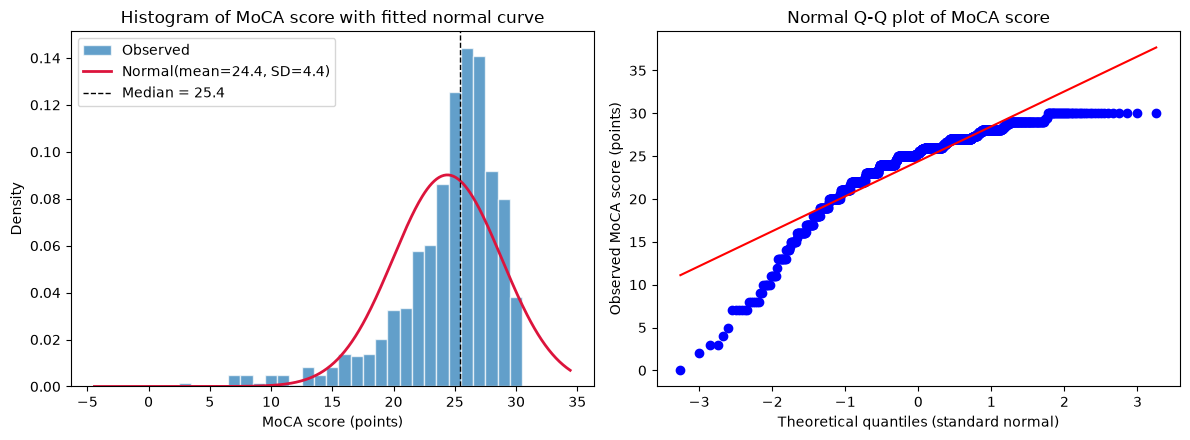

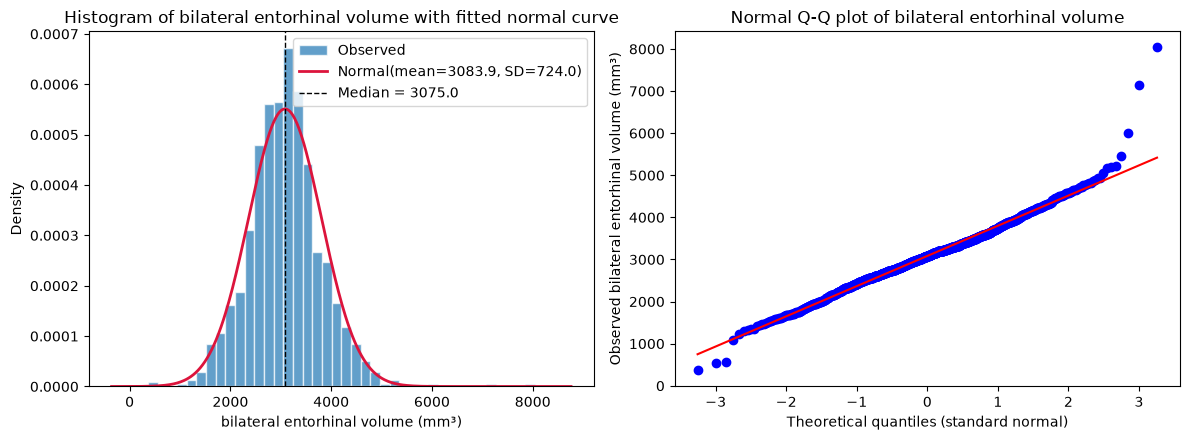

In [25]:
def hist_qq(x, name, unit, bins, fname):
    x = x.dropna()
    mu, sd = x.mean(), x.std(ddof=1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    ax = axes[0]
    ax.hist(x, bins=bins, density=True, alpha=0.7, edgecolor='white', label='Observed')
    grid = np.linspace(x.min() - sd, x.max() + sd, 400)
    ax.plot(grid, stats.norm.pdf(grid, mu, sd), color='crimson', lw=2,
            label=f'Normal(mean={mu:.1f}, SD={sd:.1f})')
    ax.axvline(x.median(), color='black', ls='--', lw=1, label=f'Median = {x.median():.1f}')
    ax.set_xlabel(f'{name} ({unit})'); ax.set_ylabel('Density')
    ax.set_title(f'Histogram of {name} with fitted normal curve')
    ax.legend()

    stats.probplot(x, dist='norm', plot=axes[1])
    axes[1].set_title(f'Normal Q-Q plot of {name}')
    axes[1].set_xlabel('Theoretical quantiles (standard normal)')
    axes[1].set_ylabel(f'Observed {name} ({unit})')

    plt.tight_layout()
    plt.savefig(fname, dpi=200)
    plt.show()

os.makedirs('figures', exist_ok=True)
hist_qq(d['MOCATOTS'], 'MoCA score', 'points',
        np.arange(-0.5, 31.5, 1), 'figures/phase2_moca_hist_qq.png')
hist_qq(d['BILAT_ENTORHINAL'], 'bilateral entorhinal volume', 'mm³',
        40, 'figures/phase2_entorhinal_hist_qq.png')

,sex,n,mean,sd,median,skewness,excess_kurtosis,shapiro_W
0,1.0,496,3314.942,801.439,3297.5,0.493,3.460,0.969
1,2.0,731,2927.103,619.532,2953.0,-0.054,0.359,0.996


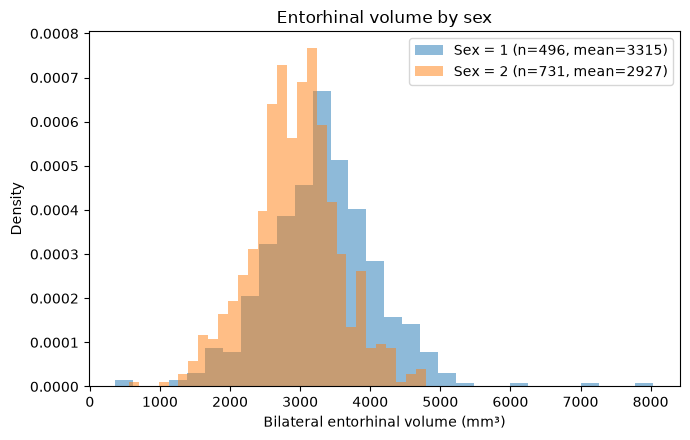

In [26]:
rows = []
for s, g in d.groupby('SEX'):
    r = distribution_summary(g['BILAT_ENTORHINAL'])
    rows.append({'sex': s, 'n': r['n'], 'mean': r['mean'], 'sd': r['sd'], 'median': r['median'],
                 'skewness': r['skewness'], 'excess_kurtosis': r['excess_kurtosis'],
                 'shapiro_W': r['shapiro_W']})
by_sex = pd.DataFrame(rows).round(3)
display(by_sex)

fig, ax = plt.subplots(figsize=(7, 4.5))
for s, lab in [(1.0, 'Sex = 1'), (2.0, 'Sex = 2')]:
    g = d.loc[d['SEX'] == s, 'BILAT_ENTORHINAL'].dropna()
    ax.hist(g, bins=30, density=True, alpha=0.5,
            label=f'{lab} (n={len(g)}, mean={g.mean():.0f})')
ax.set_xlabel('Bilateral entorhinal volume (mm³)')
ax.set_ylabel('Density')
ax.set_title('Entorhinal volume by sex')
ax.legend()
plt.tight_layout()
plt.savefig('figures/phase2_entorhinal_by_sex.png', dpi=200)
plt.show()

In [27]:
os.makedirs('reports/phase2', exist_ok=True)
summary6.to_csv('reports/phase2/table_distribution_summary.csv')
by_sex.to_csv('reports/phase2/table_entorhinal_by_sex.csv', index=False)

In [31]:
def mean_variance(x):
    """Mean (expected value) and variance of an empirical distribution."""
    x = x.dropna()
    return {
        'n': len(x),
        'mean': x.mean(),
        'variance_sample': x.var(ddof=1),      # divides by n-1 (reported)
        'variance_empirical': x.var(ddof=0),   # divides by n (empirical distribution)
        'sd': x.std(ddof=1),
        'cv': x.std(ddof=1) / x.mean(),
    }

mv = pd.DataFrame({
    'MoCA': mean_variance(d['MOCATOTS']),
    'BILAT_ENTORHINAL': mean_variance(d['BILAT_ENTORHINAL']),
}).round(4)
display(mv)

# Binary events: E = p, Var = p(1-p)
for ev in ['B', 'C']:
    xx = d[ev].dropna()
    p = xx.mean()
    print(f"{ev}: E={p:.4f}  Var=p(1-p)={p*(1-p):.4f}")

# Conditional mean and variance of MoCA given each event
rows = []
for g in ['A', 'D', 'C']:
    s = d[['MOCATOTS', g]].dropna()
    t = (s.groupby(g)['MOCATOTS']
           .agg(n='size', mean='mean', variance='var', sd='std')
           .reset_index().rename(columns={g: 'value'}))
    t.insert(0, 'event', g)
    rows.append(t)
cond_means = pd.concat(rows, ignore_index=True).round(3)
display(cond_means)

os.makedirs('reports/phase2', exist_ok=True)
mv.to_csv('reports/phase2/table_mean_variance.csv')
cond_means.to_csv('reports/phase2/table_conditional_means.csv', index=False)

,MoCA,BILAT_ENTORHINAL
n,1228.0000,1227.0000
mean,24.3930,3083.8818
variance_sample,19.5791,524125.0717
variance_empirical,19.5631,523697.9119
sd,4.4248,723.9648
cv,0.1814,0.2348


B: E=0.5326  Var=p(1-p)=0.2489
C: E=0.2502  Var=p(1-p)=0.1876


,event,value,n,mean,variance,sd
0,A,0.0,738,24.772,19.384,4.403
1,A,1.0,479,23.866,18.916,4.349
2,D,0.0,1093,24.575,19.076,4.368
3,D,1.0,127,23.101,21.343,4.620
4,C,0.0,920,25.083,14.692,3.833
5,C,1.0,307,22.313,28.579,5.346


In [32]:
s = d[['MOCATOTS', 'BILAT_ENTORHINAL']].dropna()
x = s['BILAT_ENTORHINAL']; y = s['MOCATOTS']
print("n =", len(s))

cov_matrix = s.cov()                     # sample covariance (divides by n-1)
display(cov_matrix.round(2))
cov_xy = cov_matrix.loc['MOCATOTS', 'BILAT_ENTORHINAL']
print("Cov(MoCA, entorhinal) =", round(cov_xy, 2), "points*mm^3")

# Quadrants around the means: why the covariance is positive
cx, cy = x - x.mean(), y - y.mean()
quad = pd.Series({
    'both above mean': int(((cx > 0) & (cy > 0)).sum()),
    'both below mean': int(((cx < 0) & (cy < 0)).sum()),
    'volume above, MoCA below': int(((cx > 0) & (cy < 0)).sum()),
    'volume below, MoCA above': int(((cx < 0) & (cy > 0)).sum()),
})
display(quad)
print("concordant share:", round((quad.iloc[0] + quad.iloc[1]) / quad.sum(), 3))

n = 1227


,MOCATOTS,BILAT_ENTORHINAL
MOCATOTS,19.59,760.65
BILAT_ENTORHINAL,760.65,524125.07


Cov(MoCA, entorhinal) = 760.65 points*mm^3


both above mean             437
both below mean             293
volume above, MoCA below    170
volume below, MoCA above    327
dtype: int64

concordant share: 0.595


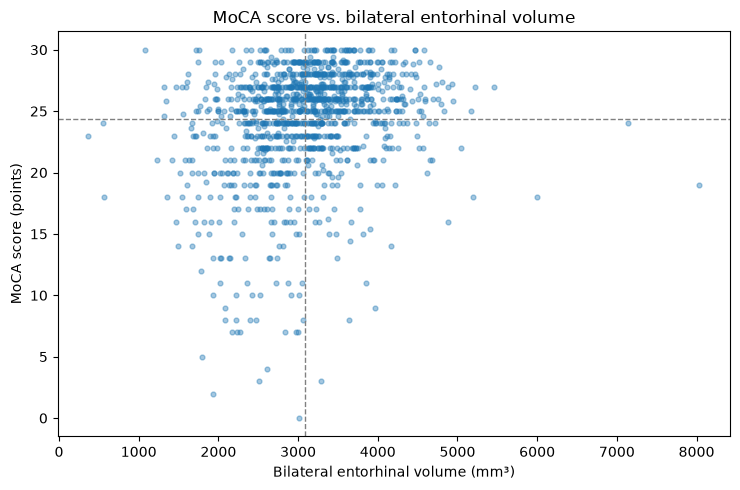

In [33]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(x, y, s=12, alpha=0.4)
ax.axvline(x.mean(), color='gray', ls='--', lw=1)
ax.axhline(y.mean(), color='gray', ls='--', lw=1)
ax.set_xlabel('Bilateral entorhinal volume (mm³)')
ax.set_ylabel('MoCA score (points)')
ax.set_title('MoCA score vs. bilateral entorhinal volume')
plt.tight_layout()
plt.savefig('figures/phase2_scatter_moca_entorhinal.png', dpi=200)
plt.show()

In [34]:
s2 = s.copy()
s2['quintile'] = pd.qcut(s2['BILAT_ENTORHINAL'], 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
quint = (s2.groupby('quintile', observed=True)
           .agg(n=('MOCATOTS', 'size'),
                entorhinal_mean=('BILAT_ENTORHINAL', 'mean'),
                moca_mean=('MOCATOTS', 'mean'),
                moca_median=('MOCATOTS', 'median'))
           .round(2))
display(quint)

,n,entorhinal_mean,moca_mean,moca_median
quintile,,,,
Q1,246,2115.85,22.11,23.8
Q2,245,2725.67,23.85,25.0
Q3,245,3077.84,25.02,26.0
Q4,245,3400.40,25.59,26.0
Q5,246,4099.46,25.38,26.0


In [35]:
# Covariance by sex
t = d[['MOCATOTS', 'BILAT_ENTORHINAL', 'SEX']].dropna()
rows = []
for sx, g in t.groupby('SEX'):
    rows.append({'sex': sx, 'n': len(g),
                 'cov': g['MOCATOTS'].cov(g['BILAT_ENTORHINAL'])})
cov_by_sex = pd.DataFrame(rows).round(1)
display(cov_by_sex)

# Sensitivity (descriptive only; no observation is removed from the analysis)
z = (x - x.mean()) / x.std(ddof=1)
keep = z.abs() <= 4
print("excluded:", int((~keep).sum()),
      "| cov without them:", round(s.loc[keep, 'MOCATOTS'].cov(s.loc[keep, 'BILAT_ENTORHINAL']), 1))

# For scale only (formal correlation and inference: Phase 4)
print("Pearson r:", round(x.corr(y), 3),
      "| Spearman:", round(x.corr(y, method='spearman'), 3))

,sex,n,cov
0,1.0,496,597.5
1,2.0,731,907.3


excluded: 3 | cov without them: 801.0
Pearson r: 0.237 | Spearman: 0.263


In [36]:
cov_matrix.round(4).to_csv('reports/phase2/table_covariance_matrix.csv')
quint.to_csv('reports/phase2/table_entorhinal_quintiles.csv')
cov_by_sex.to_csv('reports/phase2/table_cov_by_sex.csv', index=False)

In [37]:
def bayes_update(d, hyp, ev):
    """Bayes' theorem with empirical frequencies: P(hyp | ev) from P(ev | hyp) and P(hyp)."""
    s = d[[hyp, ev]].dropna().astype(float)
    n = len(s)
    p_h = s[hyp].mean()                                   # prior P(H)
    p_e_h = s.loc[s[hyp] == 1, ev].mean()                 # likelihood P(E | H)
    p_e_nh = s.loc[s[hyp] == 0, ev].mean()                # P(E | not H)
    p_e = p_e_h * p_h + p_e_nh * (1 - p_h)                # law of total probability
    post = p_e_h * p_h / p_e                              # posterior P(H | E)
    direct = s.loc[s[ev] == 1, hyp].mean()                # direct empirical P(H | E)

In [ ]:
def bayes_update(d, hyp, ev):
    """Bayes' theorem with empirical frequencies: P(hyp | ev) from P(ev | hyp) and P(hyp)."""

    s = d[[hyp, ev]].dropna().astype(float)
    n = len(s)
    
    if n == 0:
        return None


    p_h = s[hyp].mean()                                   # prior P(H)
    p_e_h = s.loc[s[hyp] == 1, ev].mean()                 # likelihood P(E | H)
    p_e_nh = s.loc[s[hyp] == 0, ev].mean()                # P(E | not H)
    
   
    p_e = p_e_h * p_h + p_e_nh * (1 - p_h)                
    

    post = (p_e_h * p_h / p_e) if p_e > 0 else 0.0
    direct = s.loc[s[ev] == 1, hyp].mean()                # direct empirical P(H | E)


    p_ne_h, p_ne_nh = 1 - p_e_h, 1 - p_e_nh
    denom_neg = (p_ne_h * p_h + p_ne_nh * (1 - p_h))
    
    post_neg = (p_ne_h * p_h / denom_neg) if denom_neg > 0 else 0.0
    

    subset_ev0 = s.loc[s[ev] == 0, hyp]
    direct_neg = subset_ev0.mean() if not subset_ev0.empty else 0.0

    lr = (p_e_h / p_e_nh) if p_e_nh > 0 else float('inf')
    
    return {
        'n': n, 
        'prior_P(H)': p_h,
        'P(E|H)': p_e_h, 
        'P(E|not H)': p_e_nh, 
        'P(E)': p_e,
        'posterior_bayes': post, 
        'posterior_direct': direct,
        'posterior_neg_bayes': post_neg, 
        'posterior_neg_direct': direct_neg,
        'likelihood_ratio': lr,
        'prior_odds': p_h / (1 - p_h) if p_h < 1 else float('inf'), 
        'posterior_odds': post / (1 - post) if post < 1 else float('inf'),
    }

bayes_tab = pd.DataFrame({
    'H=B, E=C (low MoCA given low entorhinal)': bayes_update(d, 'B', 'C'),
    'H=B, E=A (low MoCA given hypertension)':   bayes_update(d, 'B', 'A'),
}).round(4)

display(bayes_tab)



,"H=B, E=C (low MoCA given low entorhinal)","H=B, E=A (low MoCA given hypertension)"
n,1227.0000,1217.0000
prior_P(H),0.5330,0.5308
P(E|H),0.3364,0.4520
P(E|not H),0.1518,0.3275
P(E),0.2502,0.3936
posterior_bayes,0.7166,0.6096
posterior_direct,0.7166,0.6096
posterior_neg_bayes,0.4717,0.4797
posterior_neg_direct,0.4717,0.4797
likelihood_ratio,2.2155,1.3802


In [43]:
import pandas as pd
import numpy as np
import os

def bayes_update(d, hyp, ev):
    """Bayes' theorem with empirical frequencies: P(hyp | ev) from P(ev | hyp) and P(hyp)."""
    
    s = d[[hyp, ev]].dropna().astype(float)
    n = len(s)
    if n == 0: return None

    p_h = s[hyp].mean()                                   # prior P(H)
    
    subset_h = s.loc[s[hyp] == 1, ev]
    p_e_h = subset_h.mean() if not subset_h.empty else 0.0 # P(E | H)
    
    subset_nh = s.loc[s[hyp] == 0, ev]
    p_e_nh = subset_nh.mean() if not subset_nh.empty else 0.0 # P(E | not H)
    
    p_e = p_e_h * p_h + p_e_nh * (1 - p_h)                
    post = (p_e_h * p_h / p_e) if p_e > 0 else 0.0
    
    subset_e = s.loc[s[ev] == 1, hyp]
    direct = subset_e.mean() if not subset_e.empty else 0.0


    p_ne_h, p_ne_nh = 1 - p_e_h, 1 - p_e_nh
    denom_neg = (p_ne_h * p_h + p_ne_nh * (1 - p_h))
    post_neg = (p_ne_h * p_h / denom_neg) if denom_neg > 0 else 0.0
    
    subset_ne = s.loc[s[ev] == 0, hyp]
    direct_neg = subset_ne.mean() if not subset_ne.empty else 0.0

   
    lr = (p_e_h / p_e_nh) if p_e_nh > 0 else float('inf')
    prior_odds = p_h / (1 - p_h) if p_h < 1 else float('inf')
    post_odds = post / (1 - post) if post < 1 else float('inf')


    return {
        'n': n, 
        'prior_P(H)': p_h,
        'P(E|H)': p_e_h, 
        'P(E|not H)': p_e_nh, 
        'P(E)': p_e,
        'posterior_bayes': post, 
        'posterior_direct': direct,
        'posterior_neg_bayes': post_neg, 
        'posterior_neg_direct': direct_neg,
        'likelihood_ratio': lr,
        'prior_odds': prior_odds, 
        'posterior_odds': post_odds,
    }

bayes_tab = pd.DataFrame({
    'H=B, E=C (low MoCA given low entorhinal)': bayes_update(d, 'B', 'C'),
    'H=B, E=A (low MoCA given hypertension)':   bayes_update(d, 'B', 'A'),
}).round(4)
display(bayes_tab)

# تحلیل حساسیت
res_bc = bayes_update(d, 'B', 'C')
lr_val = res_bc['likelihood_ratio']
prior_obs = res_bc['prior_P(H)']
priors = [0.2, 0.3, 0.4, 0.5, prior_obs, 0.7]

sens = pd.DataFrame({
    'prior_P(B)': priors,
    'posterior_P(B|C)': [( (pr/(1-pr)*lr_val) / (1 + pr/(1-pr)*lr_val) ) if pr < 1 else 1.0 for pr in priors],
}).round(4)
display(sens)

assert abs(res_bc['posterior_bayes'] - res_bc['posterior_direct']) < 1e-10
assert abs(res_bc['posterior_neg_bayes'] - res_bc['posterior_neg_direct']) < 1e-10

os.makedirs('reports/phase2', exist_ok=True)
bayes_tab.to_csv('reports/phase2/table_bayes.csv')
sens.to_csv('reports/phase2/table_bayes_prior_sensitivity.csv', index=False)



,"H=B, E=C (low MoCA given low entorhinal)","H=B, E=A (low MoCA given hypertension)"
n,1227.0000,1217.0000
prior_P(H),0.5330,0.5308
P(E|H),0.3364,0.4520
P(E|not H),0.1518,0.3275
P(E),0.2502,0.3936
posterior_bayes,0.7166,0.6096
posterior_direct,0.7166,0.6096
posterior_neg_bayes,0.4717,0.4797
posterior_neg_direct,0.4717,0.4797
likelihood_ratio,2.2155,1.3802


,prior_P(B),posterior_P(B|C)
0,0.200,0.3565
1,0.300,0.4871
2,0.400,0.5963
3,0.500,0.6890
4,0.533,0.7166
5,0.700,0.8379
